C:\Users\VEDANT\AppData\Local\Temp\ipykernel_7208\4236406497.py:16: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start=start, end=end)["Close"]
[*********************100%***********************]  4 of 4 completed


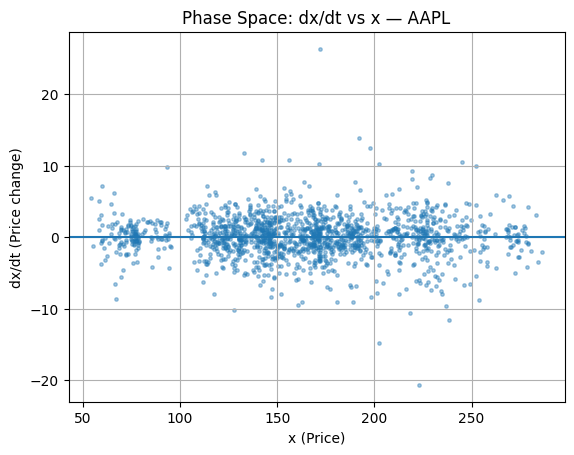

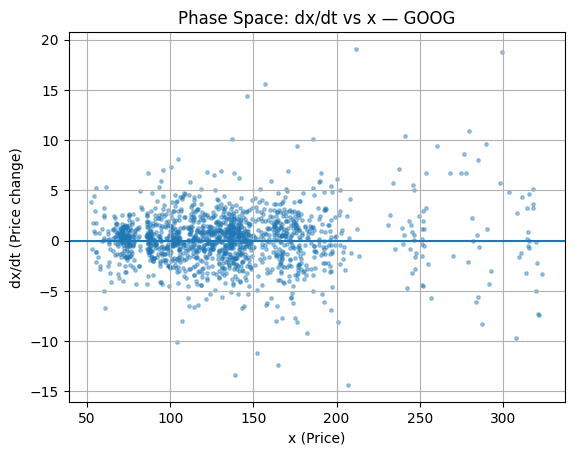

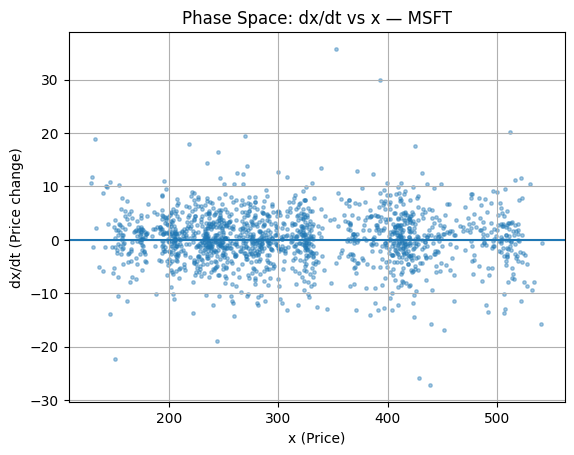

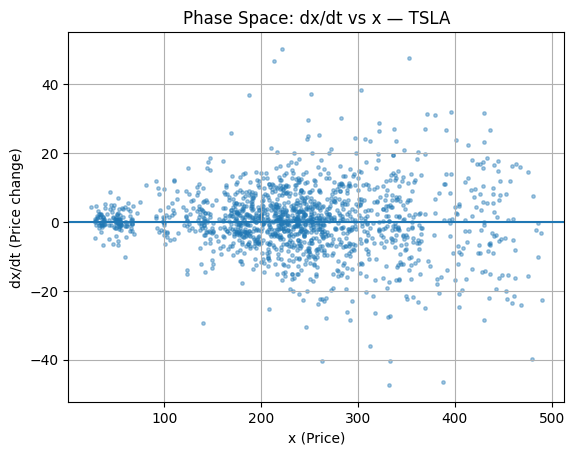

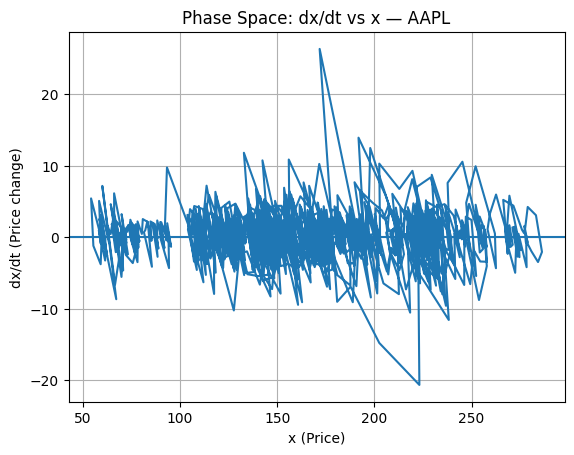

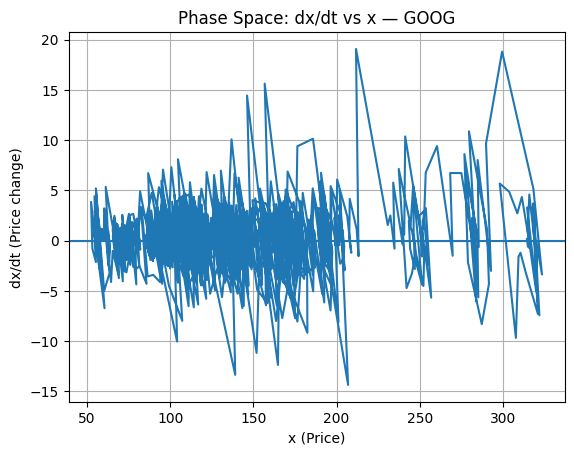

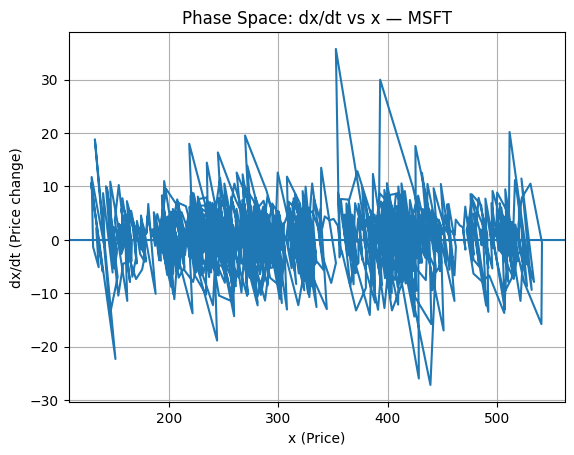

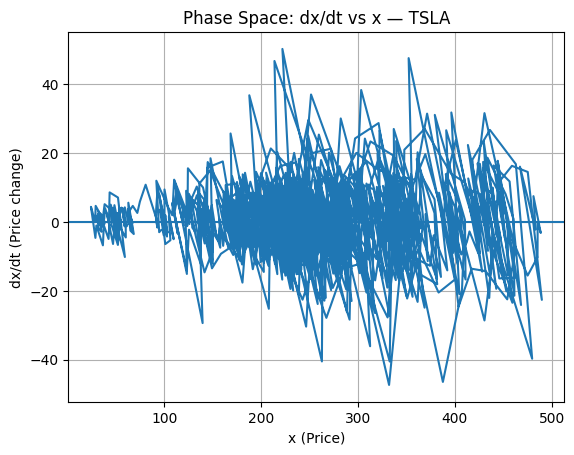

In [4]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

# -----------------------------
# Parameters
# -----------------------------
tickers = ["AAPL", "MSFT", "GOOG", "TSLA"]
start = "2020-01-01"
end   = "2025-12-31"

# -----------------------------
# Download data
# -----------------------------
data = yf.download(tickers, start=start, end=end)["Close"]

# Ensure DataFrame even for single ticker
if isinstance(data, pd.Series):
    data = data.to_frame()

# -----------------------------
# Plot dx/dt vs x
# -----------------------------
for ticker in data.columns:
    x = data[ticker].dropna().values
    
    # Discrete time derivative
    dxdt = np.diff(x)
    x_mid = x[:-1]   # align with dx/dt

    plt.figure()
    plt.scatter(
        x_mid,
        dxdt,
        s=6,
        alpha=0.4
    )
    
    plt.axhline(0)
    plt.xlabel("x (Price)")
    plt.ylabel("dx/dt (Price change)")
    plt.title(f"Phase Space: dx/dt vs x — {ticker}")
    plt.grid(True)
    plt.show()

# -----------------------------
# Plot dx/dt vs x
# -----------------------------
for ticker in data.columns:
    x = data[ticker].dropna().values
    
    # Discrete time derivative
    dxdt = np.diff(x)
    x_mid = x[:-1]   # align with dx/dt

    plt.figure()
    plt.plot(
        x_mid,
        dxdt
    )
    
    plt.axhline(0)
    plt.xlabel("x (Price)")
    plt.ylabel("dx/dt (Price change)")
    plt.title(f"Phase Space: dx/dt vs x — {ticker}")
    plt.grid(True)
    plt.show()

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_26156\4129487259.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(ticker, start=start, end=end)["Close"].dropna().values
[*********************100%***********************]  1 of 1 completed


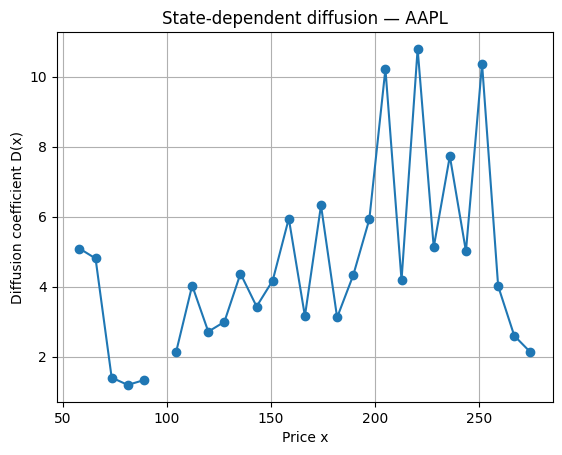

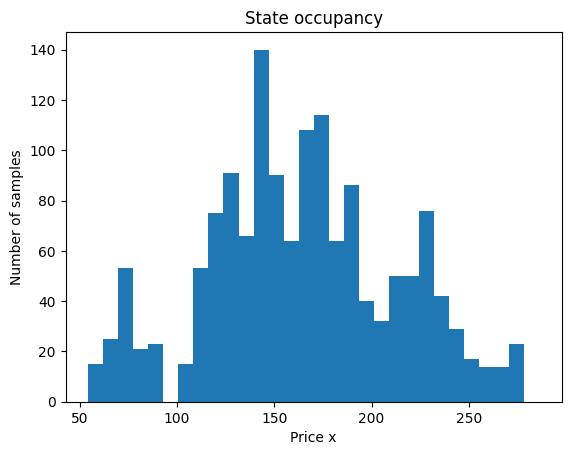

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_26156\4129487259.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(ticker, start=start, end=end)["Close"].dropna().values
[*********************100%***********************]  1 of 1 completed


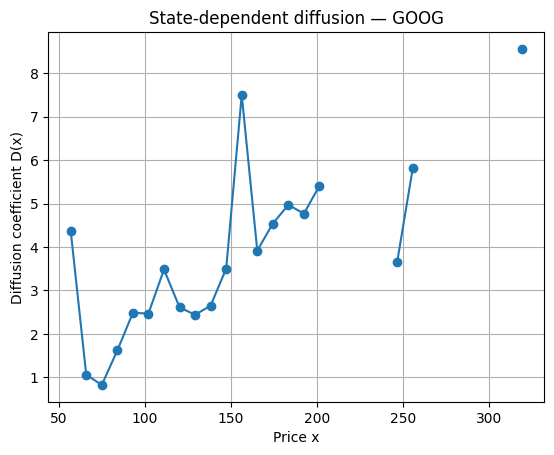

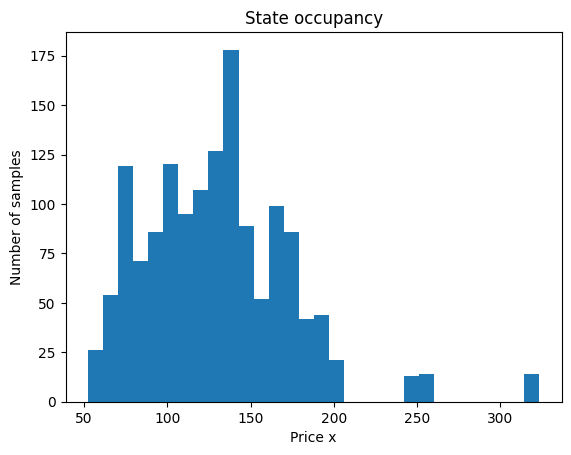

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_26156\4129487259.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(ticker, start=start, end=end)["Close"].dropna().values
[*********************100%***********************]  1 of 1 completed


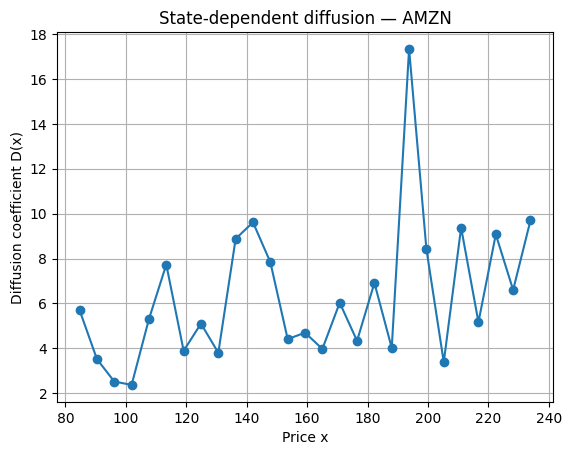

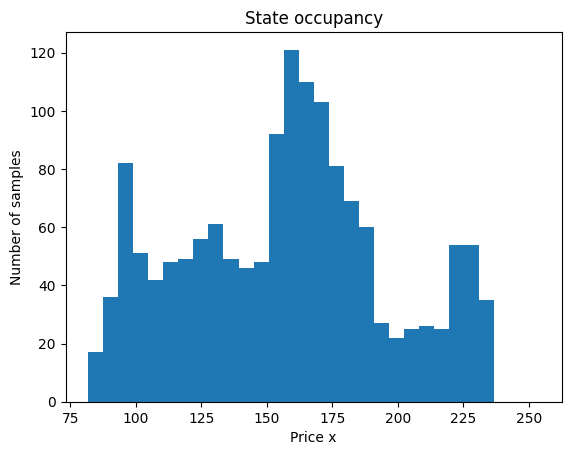

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_26156\4129487259.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(ticker, start=start, end=end)["Close"].dropna().values
[*********************100%***********************]  1 of 1 completed


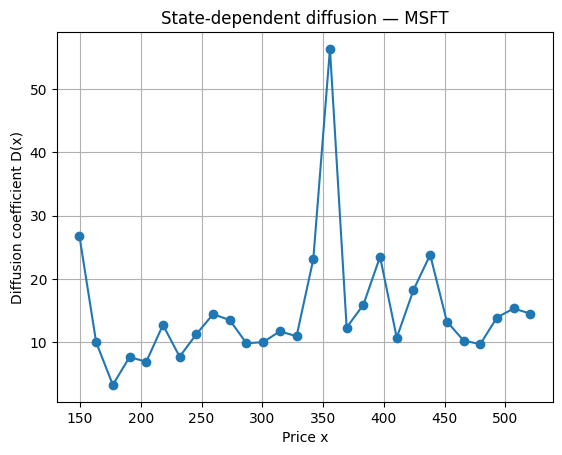

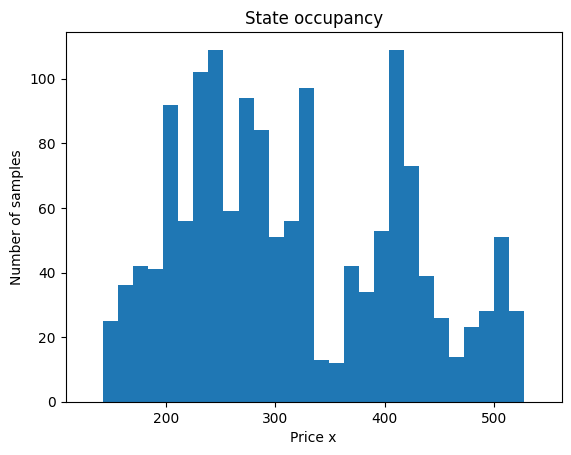

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_26156\4129487259.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(ticker, start=start, end=end)["Close"].dropna().values
[*********************100%***********************]  1 of 1 completed


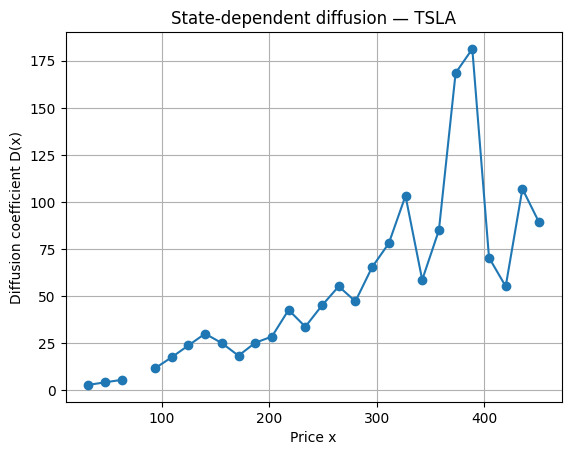

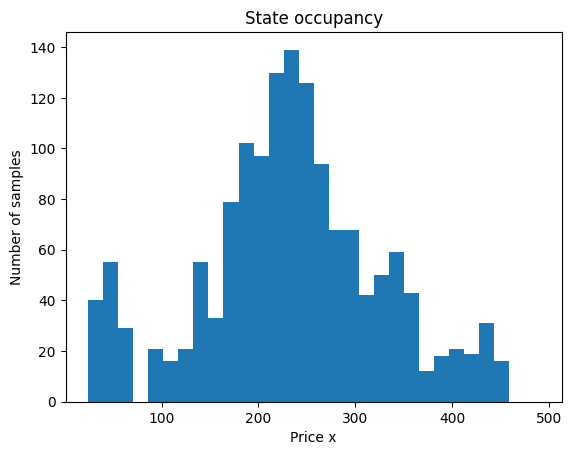

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_26156\4129487259.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(ticker, start=start, end=end)["Close"].dropna().values
[*********************100%***********************]  1 of 1 completed


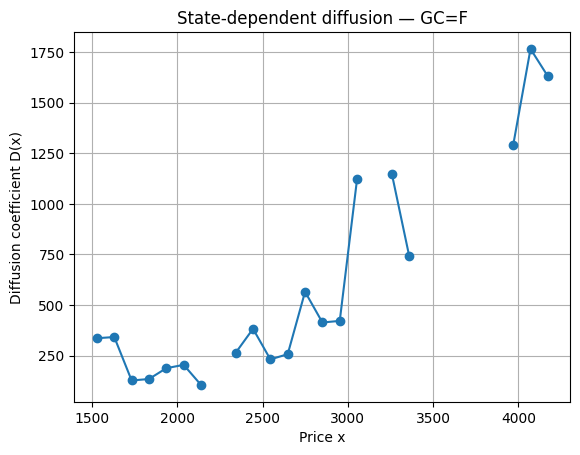

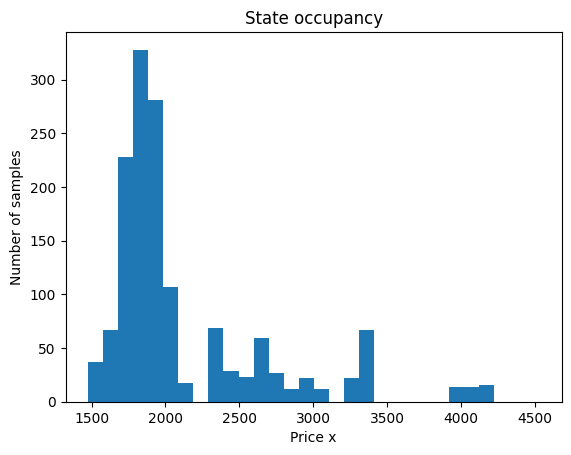

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_26156\4129487259.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(ticker, start=start, end=end)["Close"].dropna().values
[*********************100%***********************]  1 of 1 completed


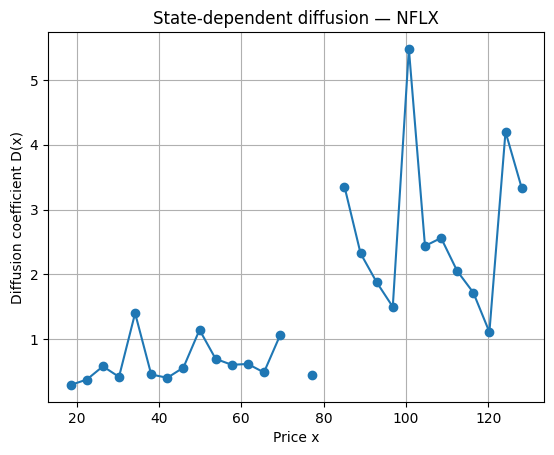

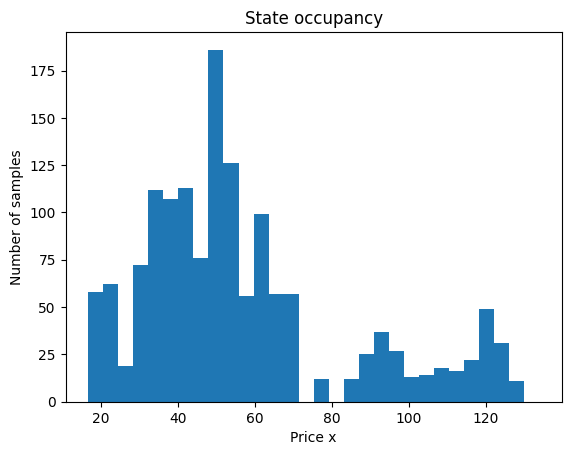

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_26156\4129487259.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(ticker, start=start, end=end)["Close"].dropna().values
[*********************100%***********************]  1 of 1 completed


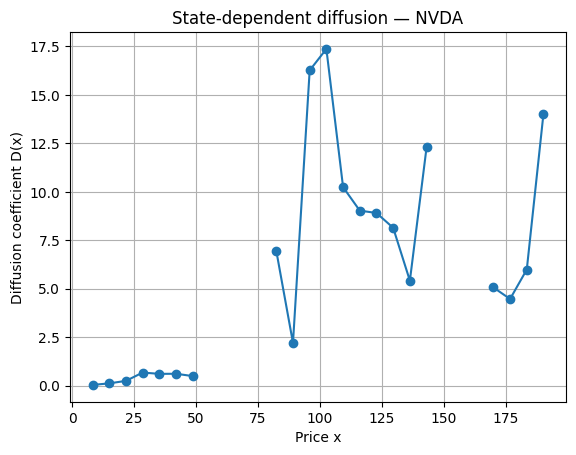

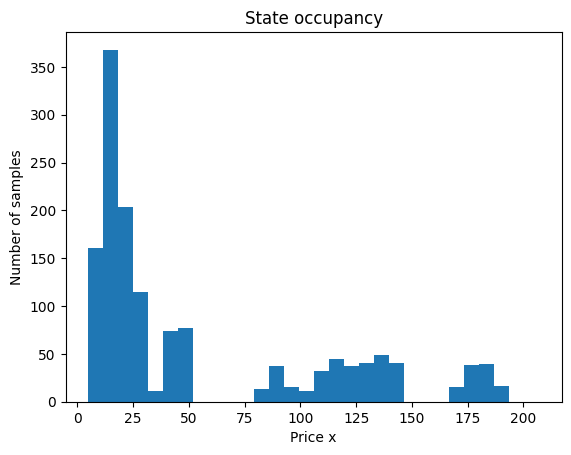

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_26156\4129487259.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(ticker, start=start, end=end)["Close"].dropna().values
[*********************100%***********************]  1 of 1 completed


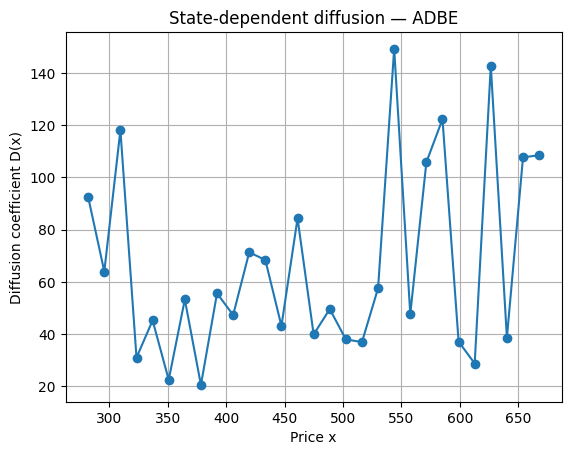

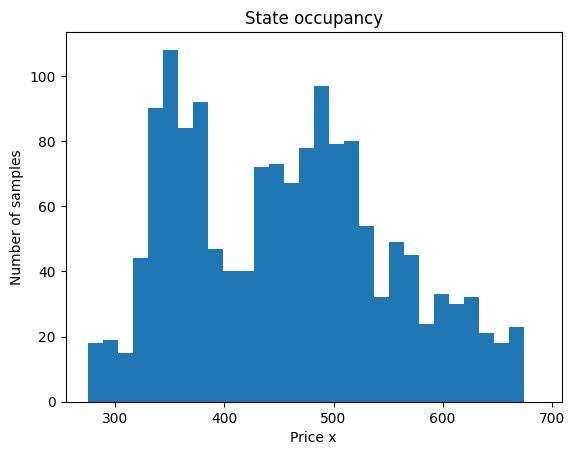

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_26156\4129487259.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(ticker, start=start, end=end)["Close"].dropna().values
[*********************100%***********************]  1 of 1 completed


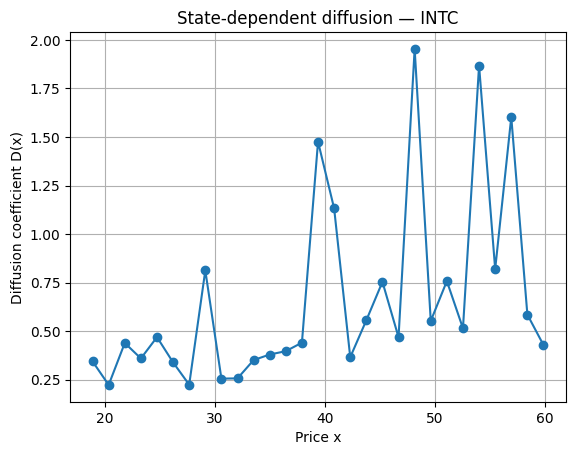

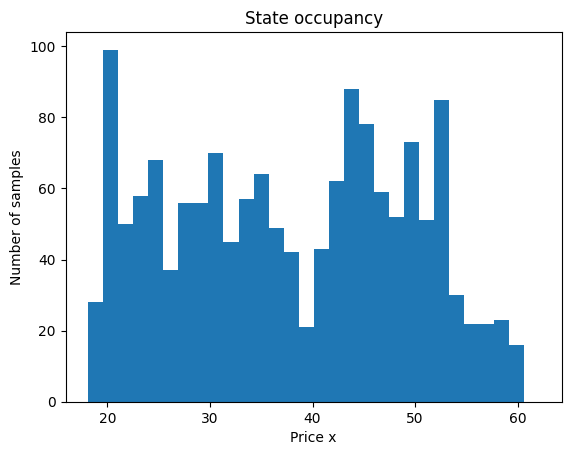

In [14]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

tickers = ["AAPL", "GOOG", "AMZN", "MSFT", "TSLA", "GC=F", "NFLX", "NVDA", "ADBE", "INTC"]
start = "2020-01-01"
end   = "2025-12-31"
n_bins = 30
dt = 1.0

for ticker in tickers:
    prices = yf.download(ticker, start=start, end=end)["Close"].dropna().values

    # --- FIXED ALIGNMENT ---
    x  = prices[:-1]
    dx = prices[1:] - prices[:-1]

    bins = np.linspace(x.min(), x.max(), n_bins + 1)
    bin_centers = 0.5 * (bins[:-1] + bins[1:])

    D = np.full(n_bins, np.nan)
    counts = np.zeros(n_bins)

    for i in range(n_bins):
        mask = (x >= bins[i]) & (x < bins[i+1])
        if np.sum(mask) > 10:
            D[i] = np.var(dx[mask], ddof=1) / (2 * dt)
            counts[i] = np.sum(mask)

    plt.figure()
    plt.plot(bin_centers, D, marker="o")
    plt.xlabel("Price x")
    plt.ylabel("Diffusion coefficient D(x)")
    plt.title(f"State-dependent diffusion — {ticker}")
    plt.grid(True)
    plt.show()

    plt.figure()
    plt.bar(bin_centers, counts, width=(bins[1]-bins[0]))
    plt.xlabel("Price x")
    plt.ylabel("Number of samples")
    plt.title("State occupancy")
    plt.show()


[*********************100%***********************]  4 of 4 completed


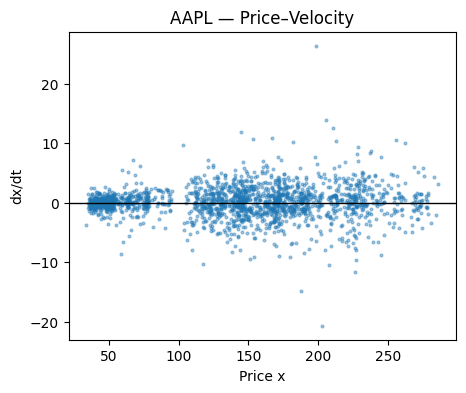

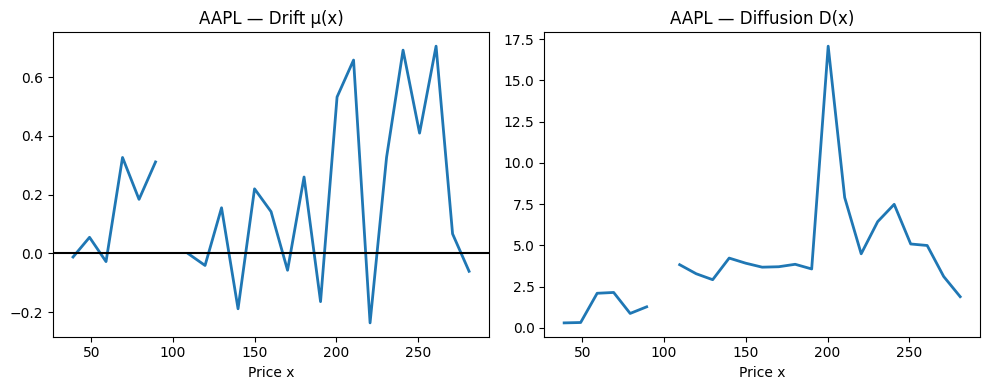

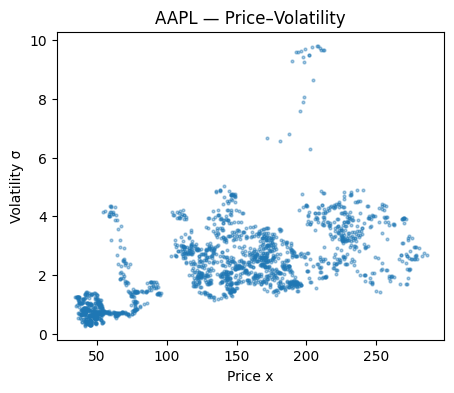

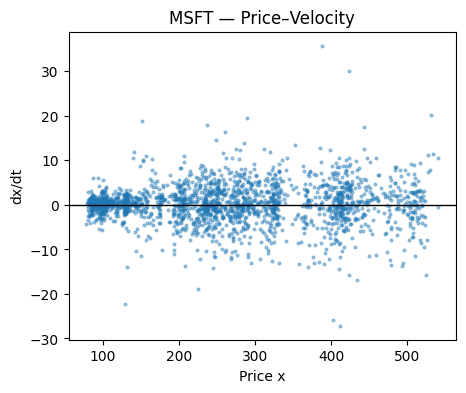

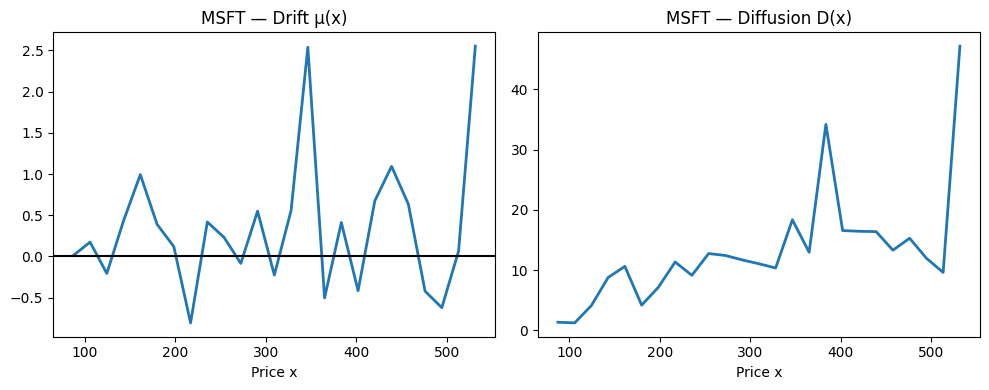

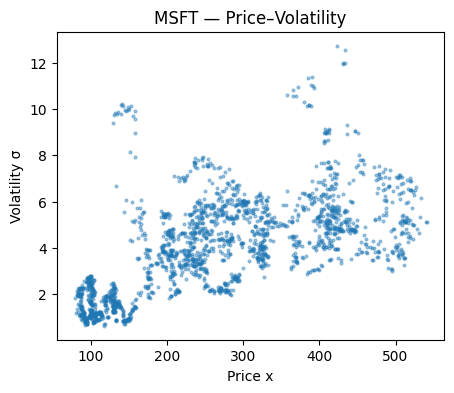

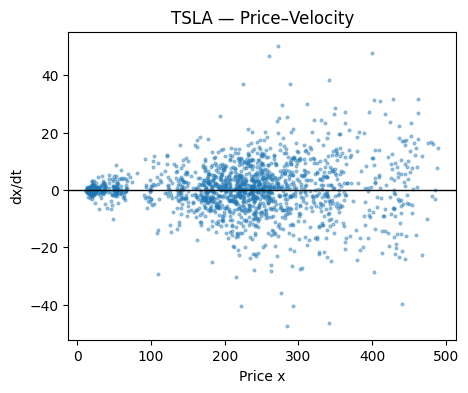

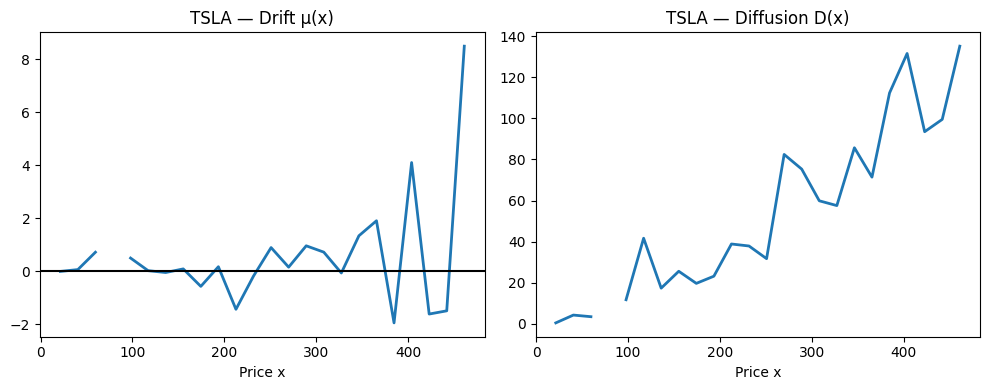

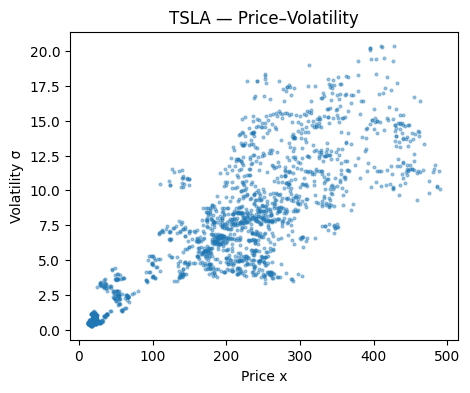

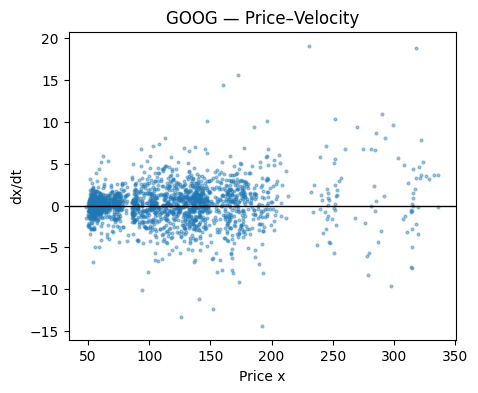

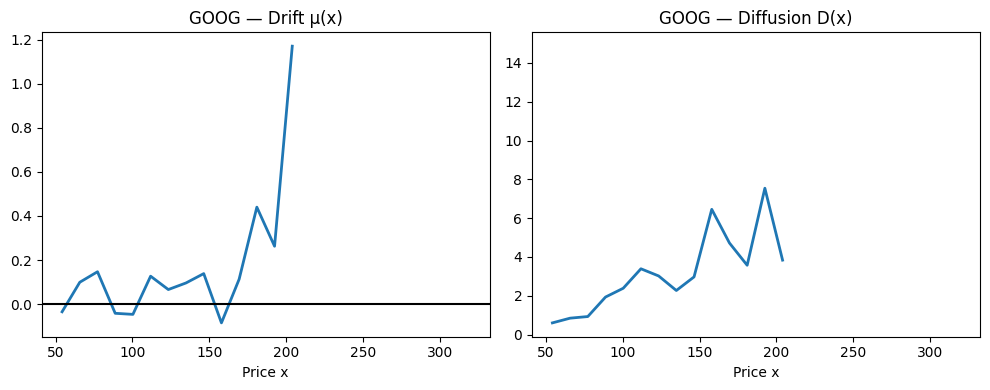

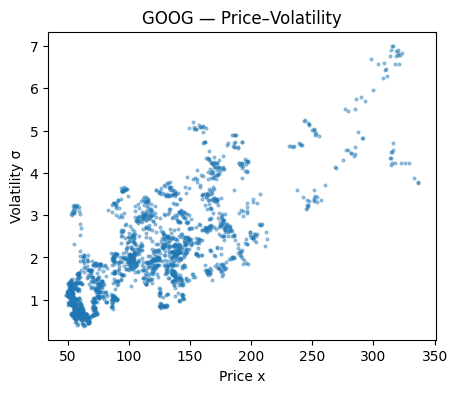

In [15]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

# -----------------------------
# PARAMETERS
# -----------------------------
tickers = ["AAPL", "MSFT", "TSLA", "GOOG"]
start = "2018-01-01"
nbins = 25
vol_window = 20

# -----------------------------
# LOAD DATA
# -----------------------------
prices = yf.download(tickers, start=start, auto_adjust=True)["Close"].dropna()

# -----------------------------
# MAIN LOOP
# -----------------------------
for ticker in tickers:
    p = prices[ticker].dropna().values

    # ---------- 1. PRICE–VELOCITY ----------
    x = p[1:]
    dx = np.diff(p)

    plt.figure(figsize=(5,4))
    plt.scatter(x, dx, s=4, alpha=0.4)
    plt.axhline(0, color="k", lw=1)
    plt.xlabel("Price x")
    plt.ylabel("dx/dt")
    plt.title(f"{ticker} — Price–Velocity")
    plt.show()

    # ---------- 2. DRIFT & DIFFUSION ----------
    bins = np.linspace(x.min(), x.max(), nbins+1)
    centers = 0.5 * (bins[:-1] + bins[1:])
    drift = np.full(nbins, np.nan)
    diffusion = np.full(nbins, np.nan)

    for i in range(nbins):
        mask = (x >= bins[i]) & (x < bins[i+1])
        if np.sum(mask) > 10:
            drift[i] = np.mean(dx[mask])
            diffusion[i] = 0.5 * np.mean(dx[mask]**2)

    fig, ax = plt.subplots(1, 2, figsize=(10,4))

    ax[0].plot(centers, drift, lw=2)
    ax[0].axhline(0, color="k")
    ax[0].set_title(f"{ticker} — Drift μ(x)")
    ax[0].set_xlabel("Price x")

    ax[1].plot(centers, diffusion, lw=2)
    ax[1].set_title(f"{ticker} — Diffusion D(x)")
    ax[1].set_xlabel("Price x")

    plt.tight_layout()
    plt.show()

    # ---------- 3. PRICE–VOLATILITY ----------
    vol = pd.Series(dx).rolling(vol_window).std().values

    plt.figure(figsize=(5,4))
    plt.scatter(x, vol, s=4, alpha=0.4)
    plt.xlabel("Price x")
    plt.ylabel("Volatility σ")
    plt.title(f"{ticker} — Price–Volatility")
    plt.show()


[*********************100%***********************]  3 of 3 completed


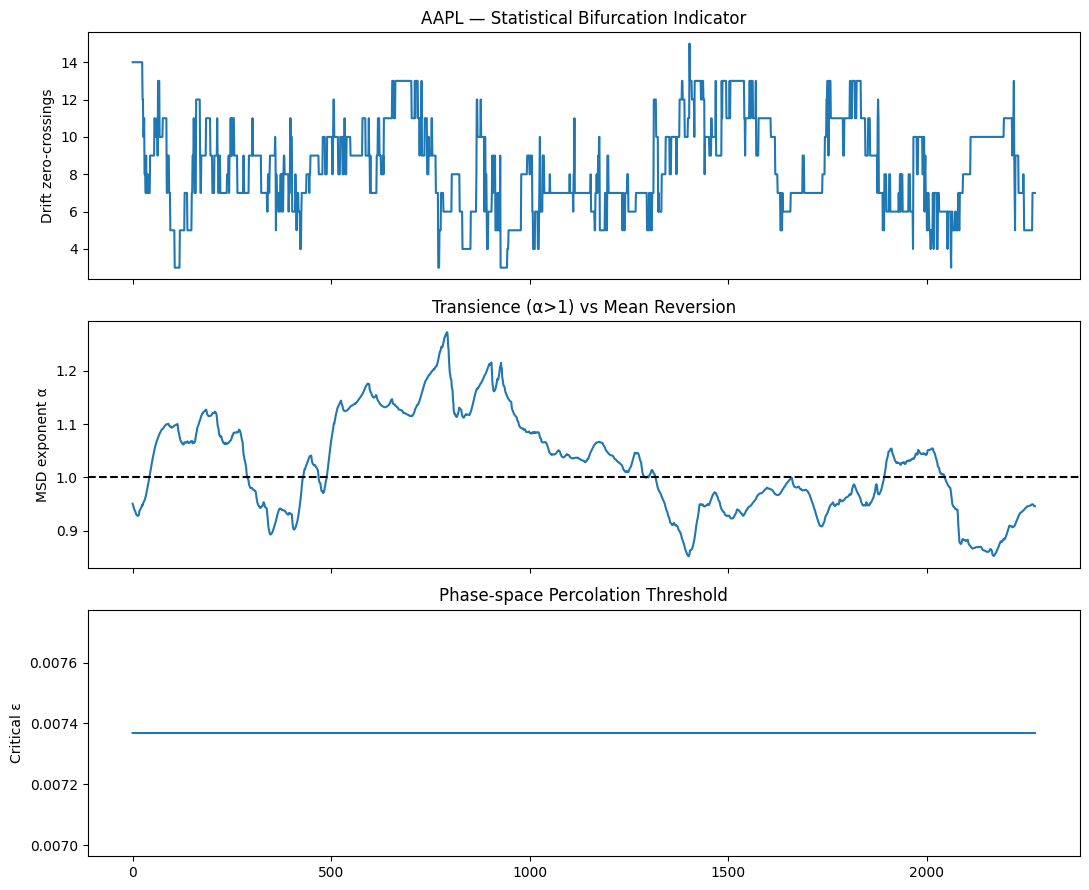

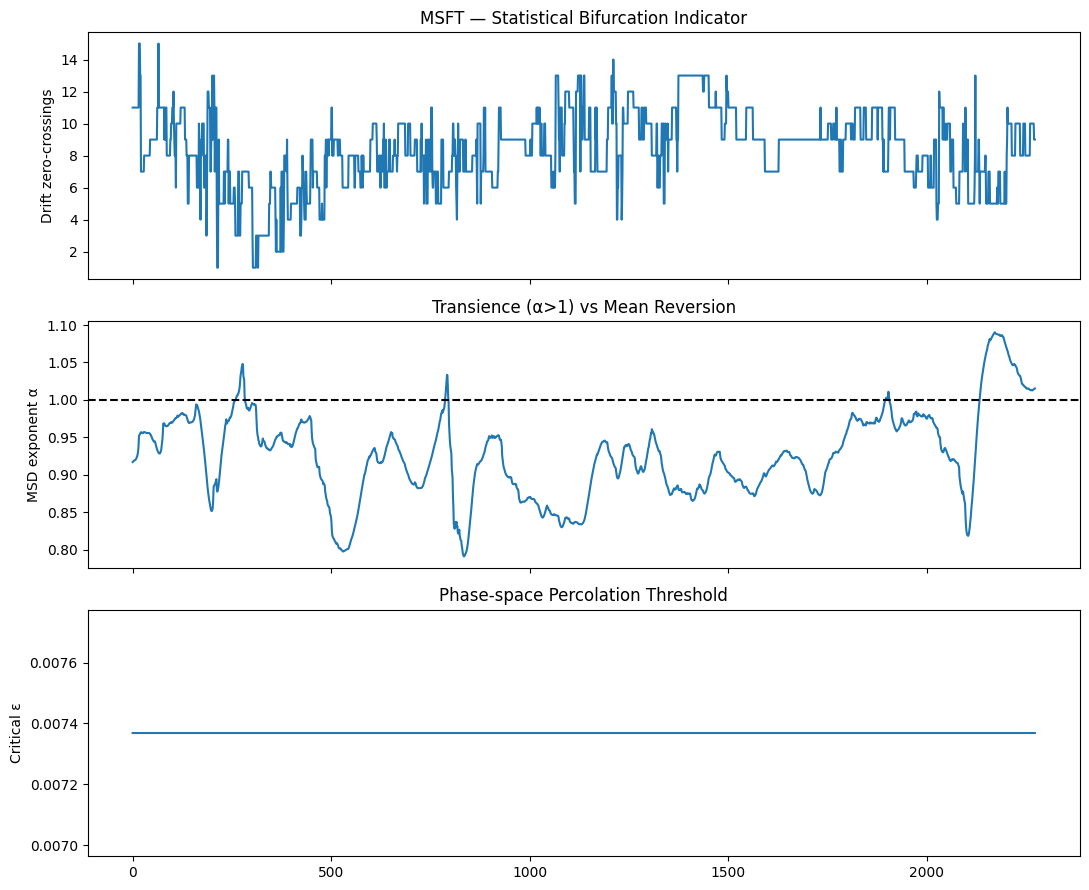

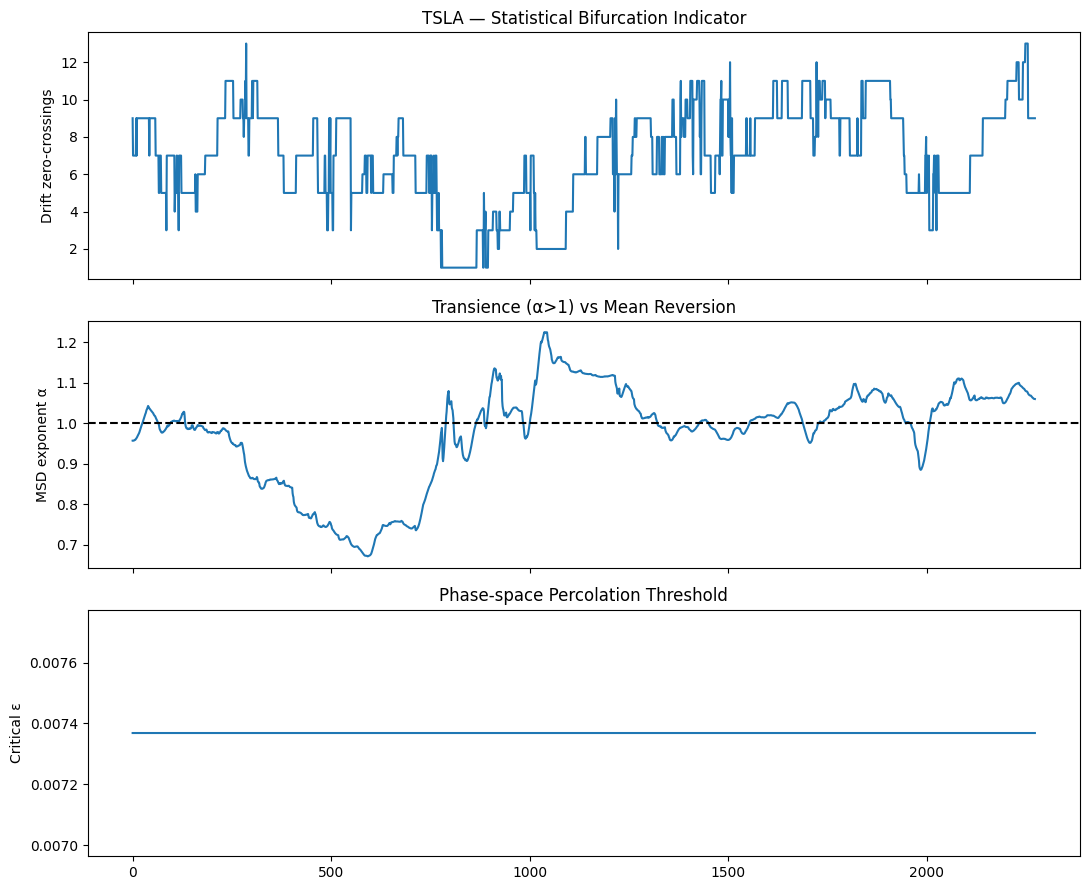

In [19]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.stats import linregress

# =============================
# PARAMETERS
# =============================
tickers = ["AAPL", "MSFT", "TSLA"]
start = "2015-01-01"

window = 500
nbins = 25
tau = 5

max_lag = 50
eps_fracs = np.linspace(0.005, 0.05, 20)  # relative phase-space scales

# =============================
# LOAD DATA
# =============================
prices = yf.download(tickers, start=start, auto_adjust=True)["Close"].dropna()

# =====================================================
# 1️⃣ BIFURCATION: drift topology changes
# =====================================================
def rolling_drift_zeros(x, dx):
    bins = np.linspace(x.min(), x.max(), nbins + 1)
    drift = np.full(nbins, np.nan)

    for i in range(nbins):
        mask = (x >= bins[i]) & (x < bins[i+1])
        if np.sum(mask) > 10:
            drift[i] = np.mean(dx[mask])

    drift = drift[~np.isnan(drift)]
    return np.sum(np.diff(np.sign(drift)) != 0)

# =====================================================
# 2️⃣ TRANSIENCE: MSD scaling exponent
# =====================================================
def msd_exponent(x):
    lags = np.arange(1, max_lag)
    msd = [(x[lag:] - x[:-lag])**2 for lag in lags]
    msd = np.array([m.mean() for m in msd])

    slope, _, _, _, _ = linregress(np.log(lags), np.log(msd))
    return slope  # α

# =====================================================
# 3️⃣ PERCOLATION: ε–connectivity transition
# =====================================================
def percolation_curve(x):
    # Delay embedding
    X = np.column_stack([x[:-tau], x[tau:]])
    scale = np.std(X)

    fractions = []

    for ef in eps_fracs:
        eps = ef * scale
        nbrs = NearestNeighbors(radius=eps)
        nbrs.fit(X)
        G = nbrs.radius_neighbors_graph(X)

        # fraction of nodes with at least one neighbor
        fractions.append(np.mean(G.sum(axis=1).A1 > 0))

    return np.array(fractions)

def critical_epsilon(fractions):
    # Percolation threshold ≈ max slope point
    grad = np.gradient(fractions, eps_fracs)
    return eps_fracs[np.argmax(grad)]

# =====================================================
# RUN ANALYSIS
# =====================================================
for ticker in tickers:
    p = prices[ticker].values
    dx = np.diff(p)

    bif_vals = []
    msd_vals = []
    eps_c_vals = []

    for i in range(window, len(p) - 1):
        xw = p[i - window : i]
        dxw = dx[i - window : i - 1]

        bif_vals.append(rolling_drift_zeros(xw[1:], dxw))
        msd_vals.append(msd_exponent(xw))

        perc = percolation_curve(xw)
        eps_c_vals.append(critical_epsilon(perc))

    # =============================
    # PLOTS
    # =============================
    fig, ax = plt.subplots(3, 1, figsize=(11, 9), sharex=True)

    ax[0].plot(bif_vals, lw=1.5)
    ax[0].set_ylabel("Drift zero-crossings")
    ax[0].set_title(f"{ticker} — Statistical Bifurcation Indicator")

    ax[1].plot(msd_vals, lw=1.5)
    ax[1].axhline(1, ls="--", color="k")
    ax[1].set_ylabel("MSD exponent α")
    ax[1].set_title("Transience (α>1) vs Mean Reversion")

    ax[2].plot(eps_c_vals, lw=1.5)
    ax[2].set_ylabel("Critical ε")
    ax[2].set_title("Phase-space Percolation Threshold")

    plt.tight_layout()
    plt.show()


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_25620\3175828798.py:22: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end)
[*********************100%***********************]  1 of 1 completed

AAPL


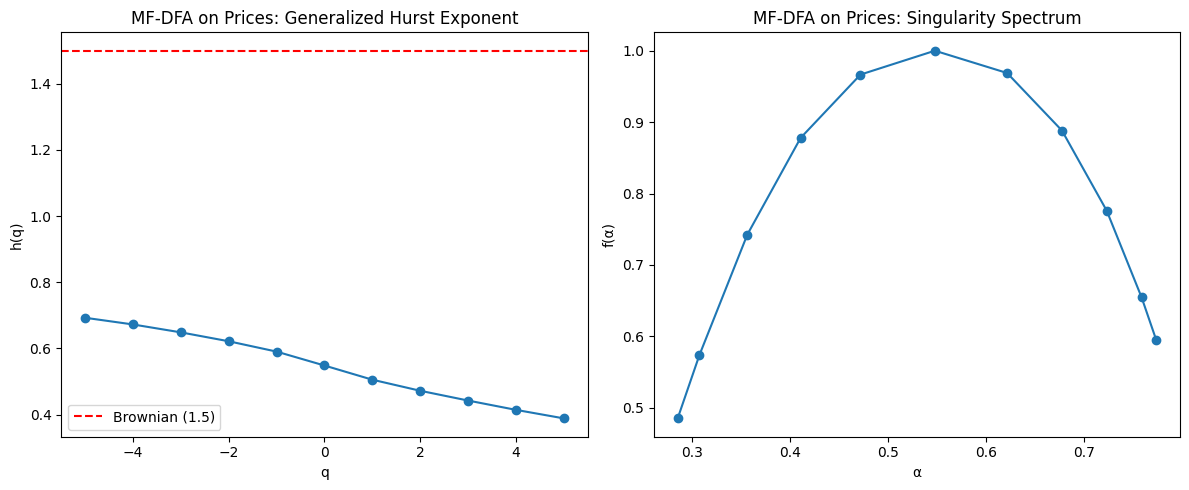

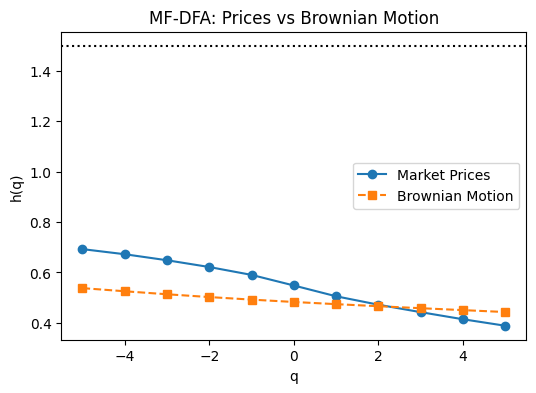

GOOG


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_25620\3175828798.py:22: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end)
[*********************100%***********************]  1 of 1 completed


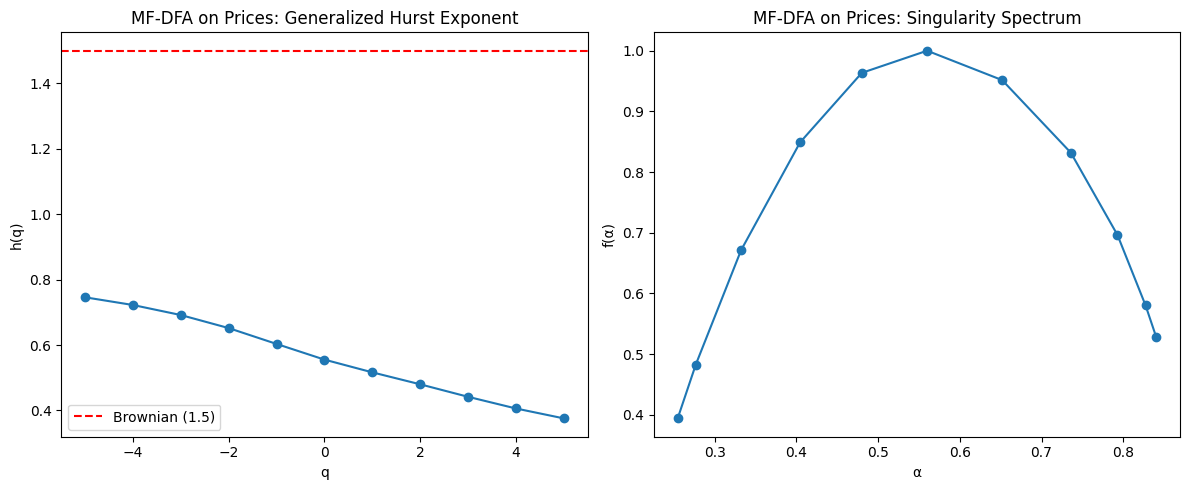

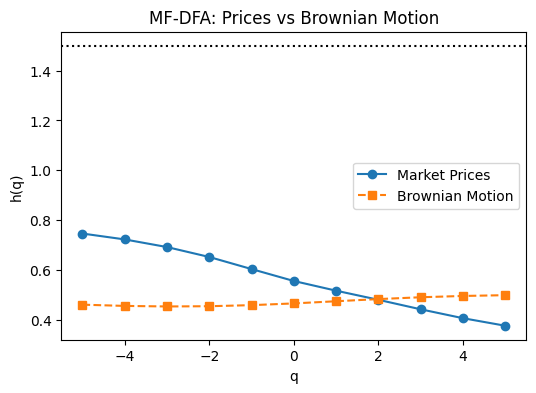

AMZN


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_25620\3175828798.py:22: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end)
[*********************100%***********************]  1 of 1 completed


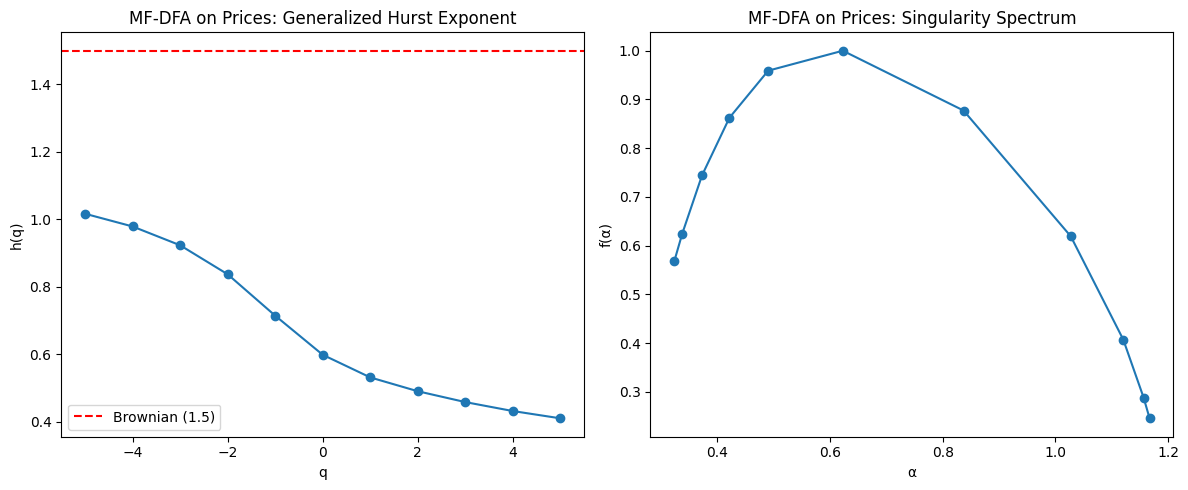

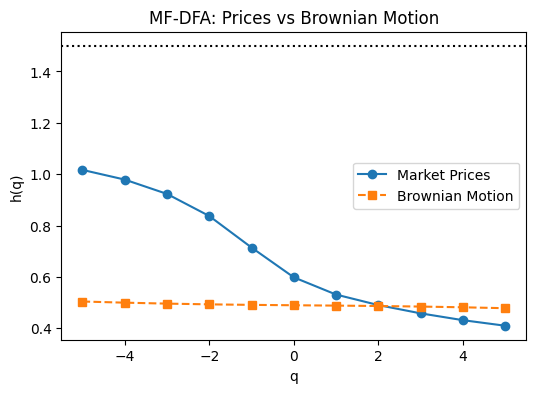

MSFT


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_25620\3175828798.py:22: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end)
[*********************100%***********************]  1 of 1 completed


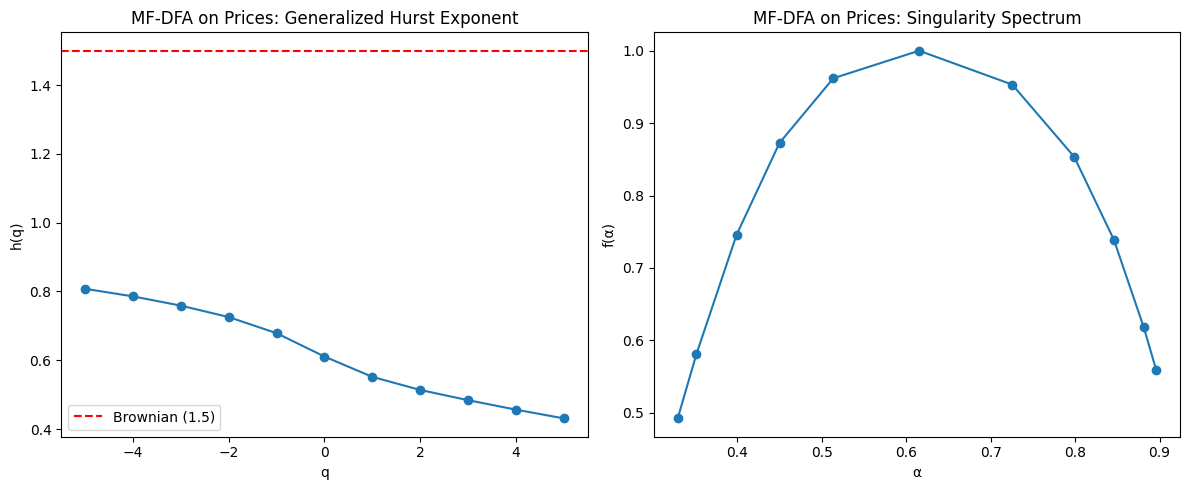

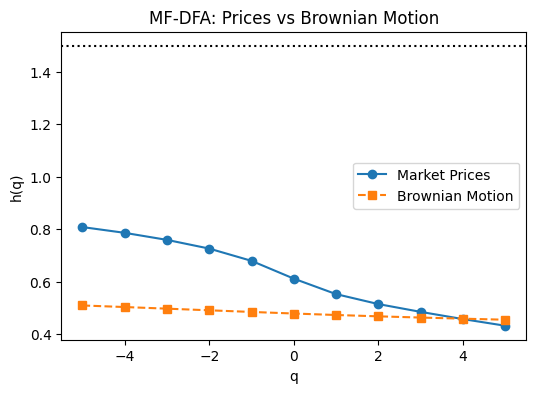

TSLA


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_25620\3175828798.py:22: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end)
[*********************100%***********************]  1 of 1 completed


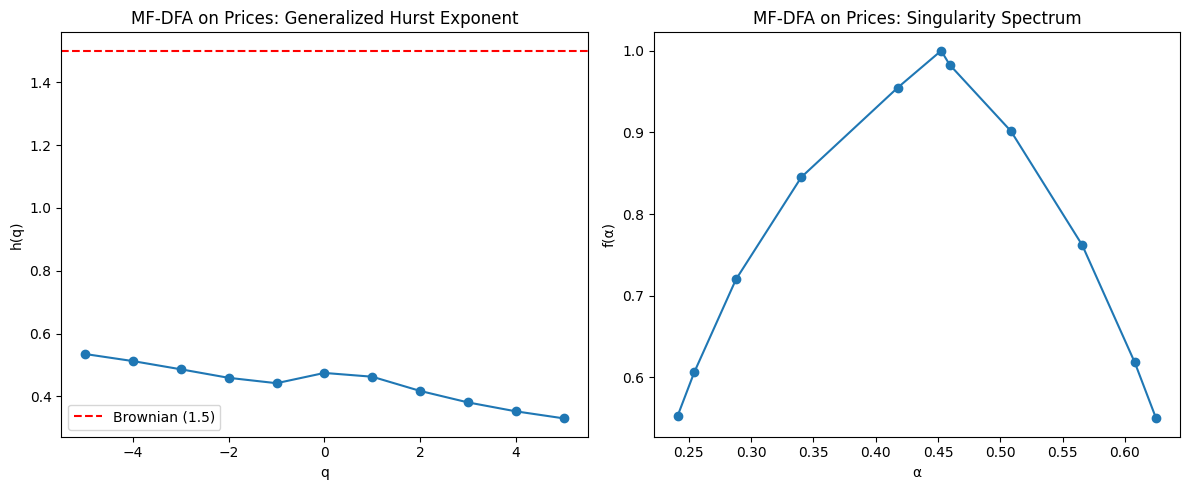

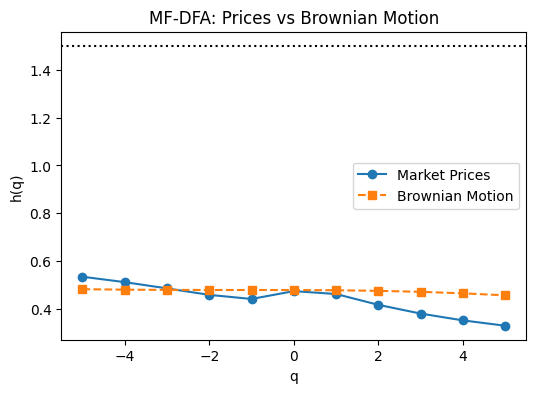

In [4]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

# --------------------------------
# PARAMETERS
# --------------------------------
tickers = ["AAPL", "GOOG", "AMZN", "MSFT", "TSLA"]
start = "2015-01-01"
end = "2026-01-01"
for ticker in tickers:
    print(ticker)
    q_list = np.arange(-5, 6)
    scale_min = 10
    scale_max = 500
    num_scales = 25

    # --------------------------------
    # LOAD PRICE DATA
    # --------------------------------
    data = yf.download(ticker, start=start, end=end)
    price = data["Close"].dropna().values
    N = len(price)

    # --------------------------------
    # MF-DFA FOR PRICES (NO INTEGRATION)
    # --------------------------------
    def mfdfa_prices(x, q_list, scale_min, scale_max, num_scales):
        scales = np.unique(
            np.logspace(np.log10(scale_min), np.log10(scale_max), num_scales).astype(int)
        )

        Fq = np.zeros((len(q_list), len(scales)))

        for i, s in enumerate(scales):
            Ns = len(x) // s
            rms = []

            for v in range(Ns):
                seg = x[v*s:(v+1)*s]
                t = np.arange(s)
                coeffs = np.polyfit(t, seg, 1)   # linear detrending
                trend = np.polyval(coeffs, t)
                rms.append(np.sqrt(np.mean((seg - trend)**2)))

            rms = np.array(rms)

            for j, q in enumerate(q_list):
                if q == 0:
                    Fq[j, i] = np.exp(0.5 * np.mean(np.log(rms**2)))
                else:
                    Fq[j, i] = (np.mean(rms**q))**(1/q)

        # Generalized Hurst exponent
        hq = np.zeros(len(q_list))
        for j in range(len(q_list)):
            coeffs = np.polyfit(np.log(scales), np.log(Fq[j]), 1)
            hq[j] = coeffs[0]

        return scales, Fq, hq

    scales, Fq, hq = mfdfa_prices(price, q_list, scale_min, scale_max, num_scales)

    # --------------------------------
    # SINGULARITY SPECTRUM
    # --------------------------------
    tau_q = hq * q_list - 1
    alpha = np.gradient(tau_q, q_list)
    f_alpha = q_list * alpha - tau_q

    # --------------------------------
    # PLOTS
    # --------------------------------
    plt.figure(figsize=(12,5))

    plt.subplot(1,2,1)
    plt.plot(q_list, hq, 'o-')
    plt.axhline(1.5, color='r', linestyle='--', label='Brownian (1.5)')
    plt.xlabel("q")
    plt.ylabel("h(q)")
    plt.title("MF-DFA on Prices: Generalized Hurst Exponent")
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(alpha, f_alpha, 'o-')
    plt.xlabel("α")
    plt.ylabel("f(α)")
    plt.title("MF-DFA on Prices: Singularity Spectrum")

    plt.tight_layout()
    plt.show()
    # --------------------------------
    # BROWNIAN MOTION BENCHMARK
    # --------------------------------
    bm = np.cumsum(np.random.normal(0, 1, N))

    _, _, hq_bm = mfdfa_prices(bm, q_list, scale_min, scale_max, num_scales)

    plt.figure(figsize=(6,4))
    plt.plot(q_list, hq, 'o-', label='Market Prices')
    plt.plot(q_list, hq_bm, 's--', label='Brownian Motion')
    plt.axhline(1.5, color='k', linestyle=':')
    plt.xlabel("q")
    plt.ylabel("h(q)")
    plt.title("MF-DFA: Prices vs Brownian Motion")
    plt.legend()
    plt.show()



Processing AAPL...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_25620\2403238548.py:61: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


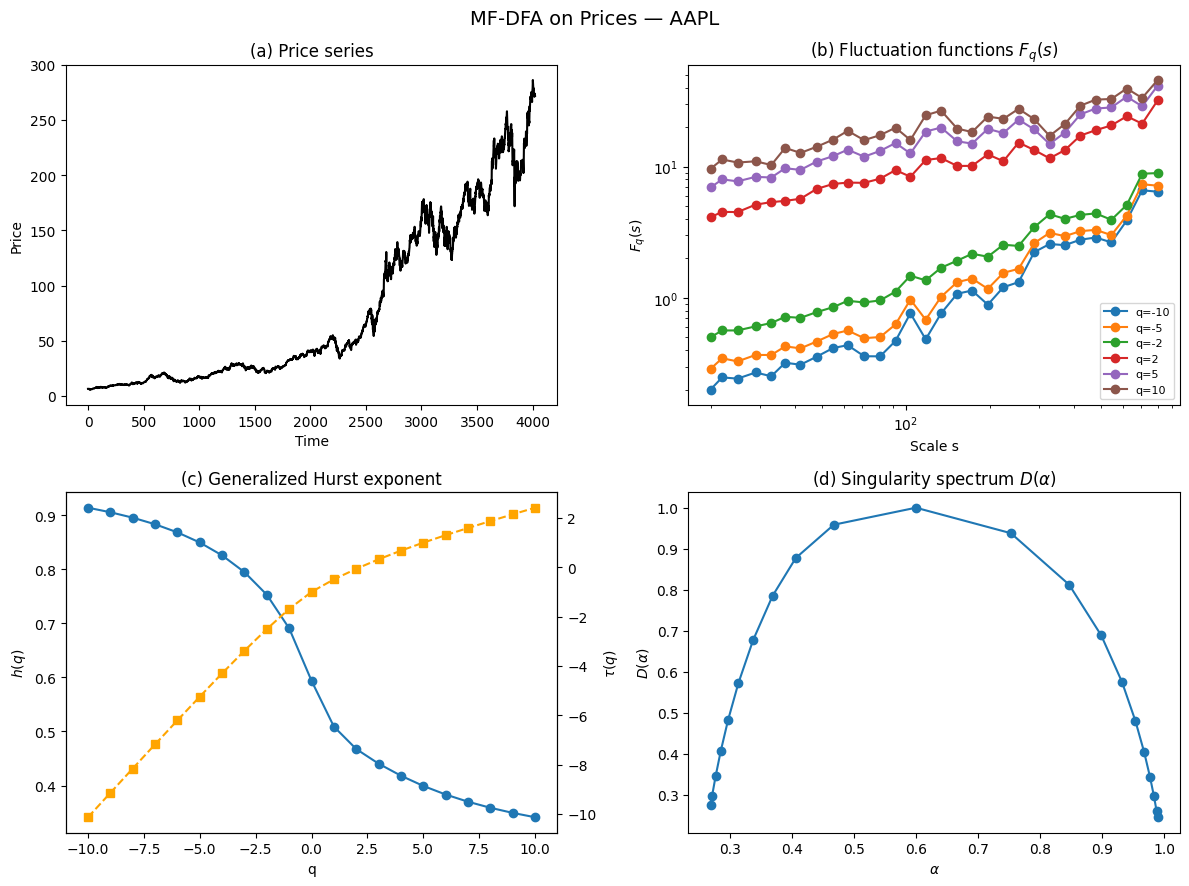

Processing MSFT...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_25620\2403238548.py:61: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


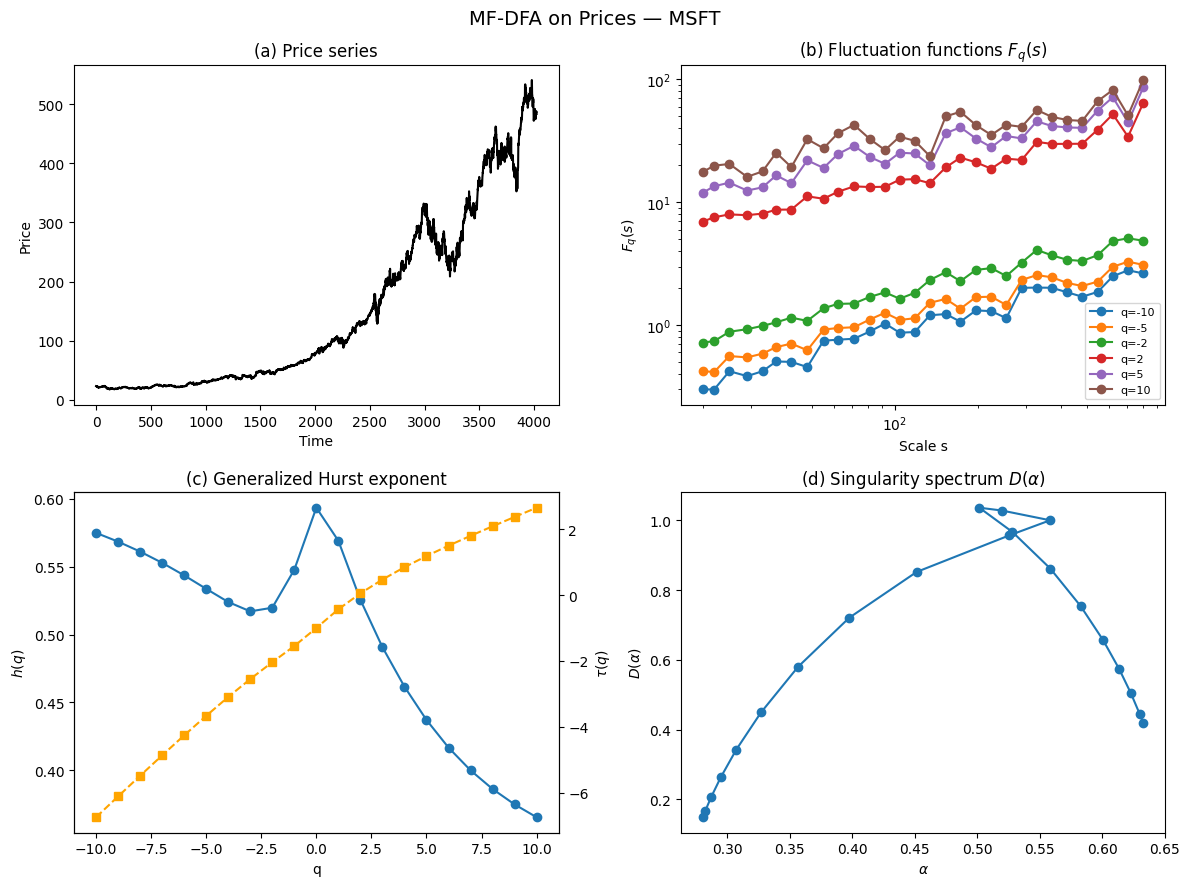

Processing GOOG...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_25620\2403238548.py:61: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


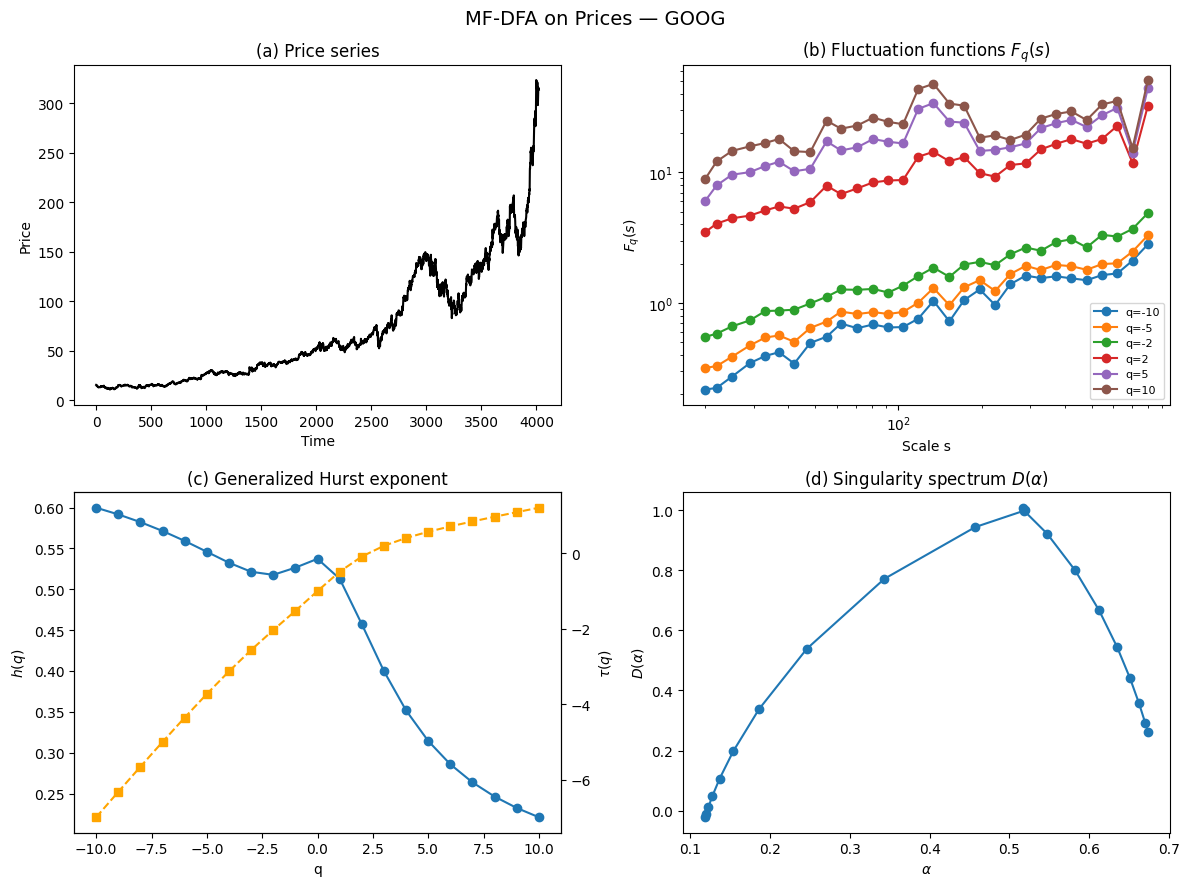

Processing TSLA...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_25620\2403238548.py:61: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


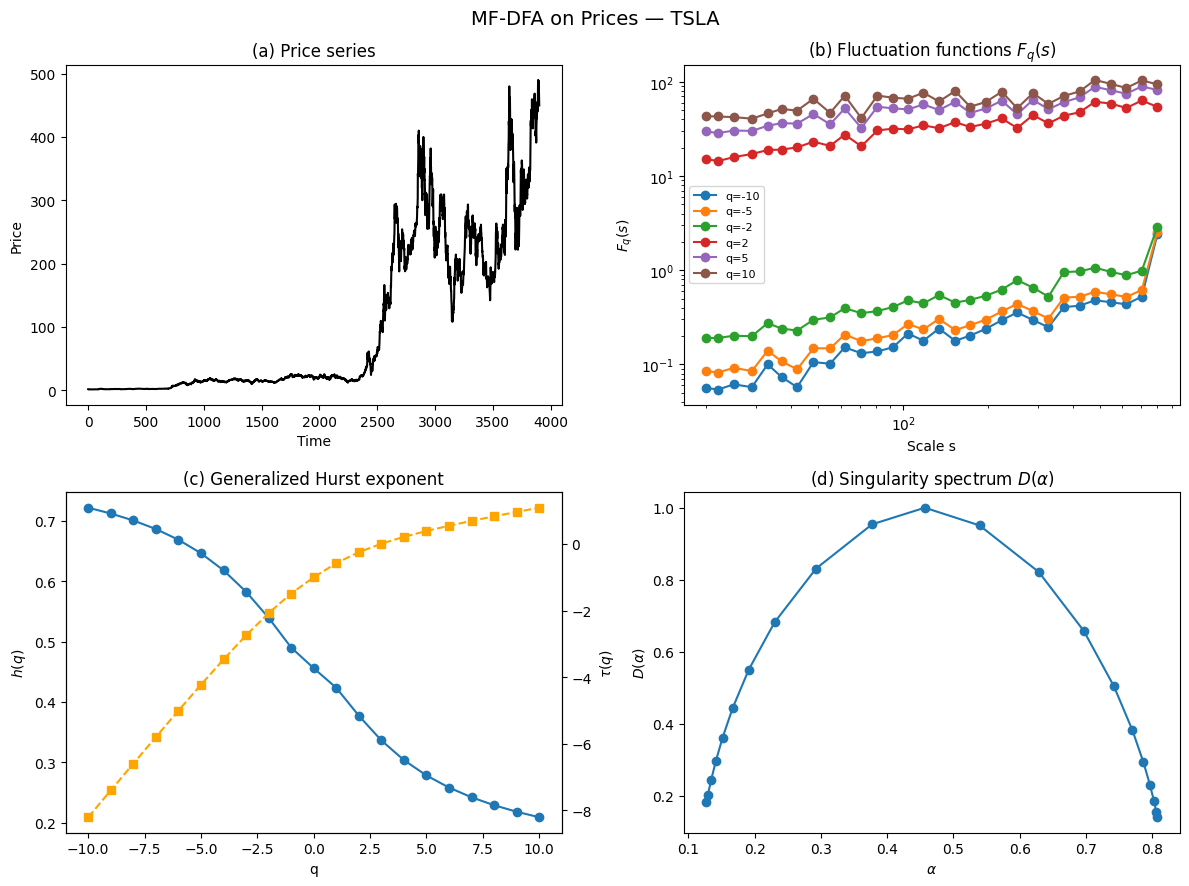

Processing AMZN...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_25620\2403238548.py:61: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


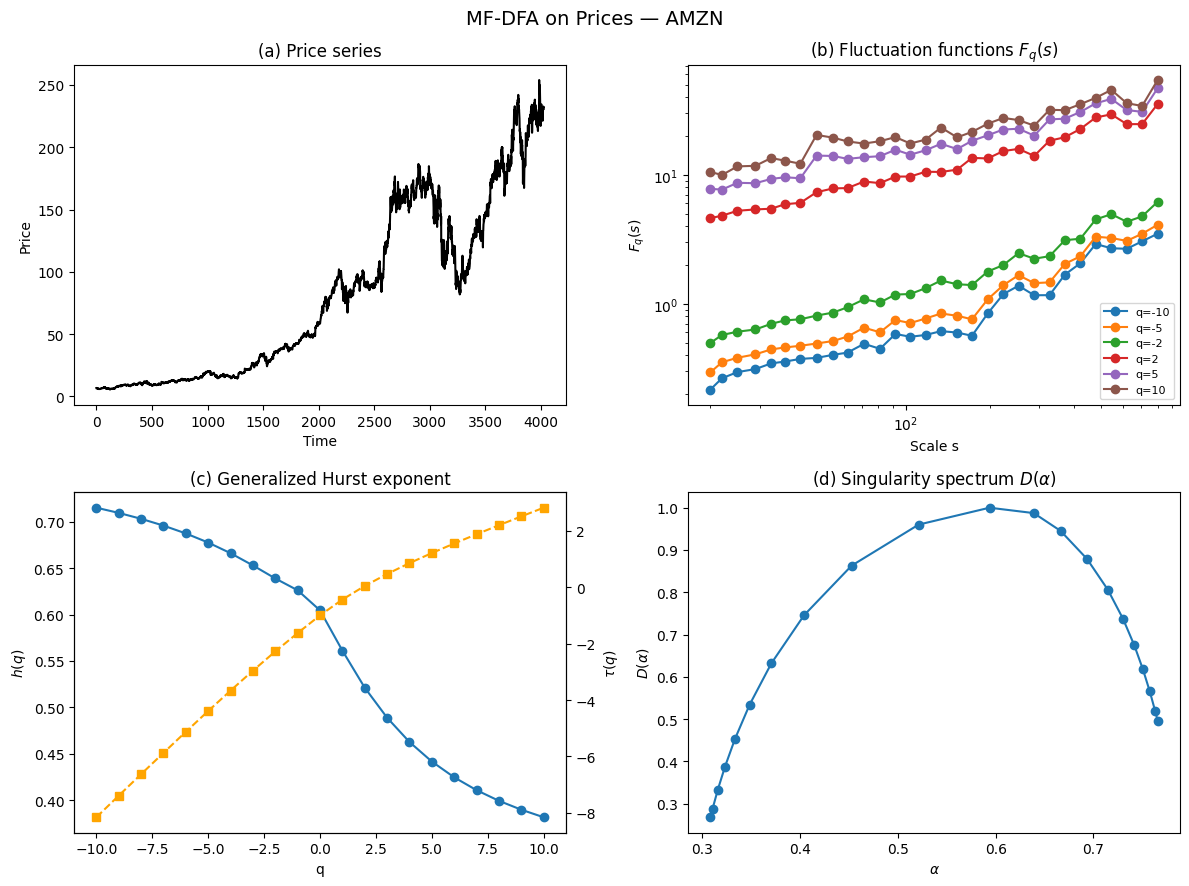

Processing GC=F...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_25620\2403238548.py:61: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


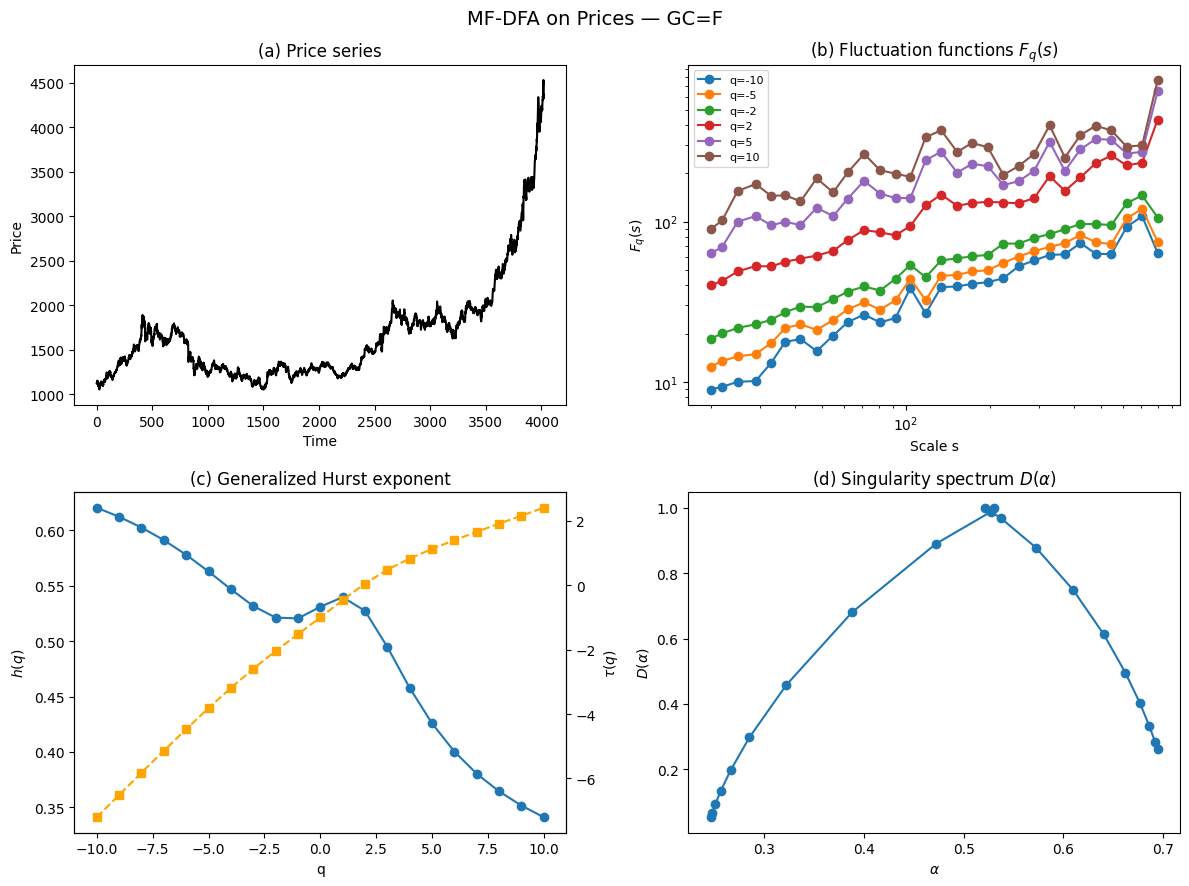

Processing BTC-USD...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_25620\2403238548.py:61: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)


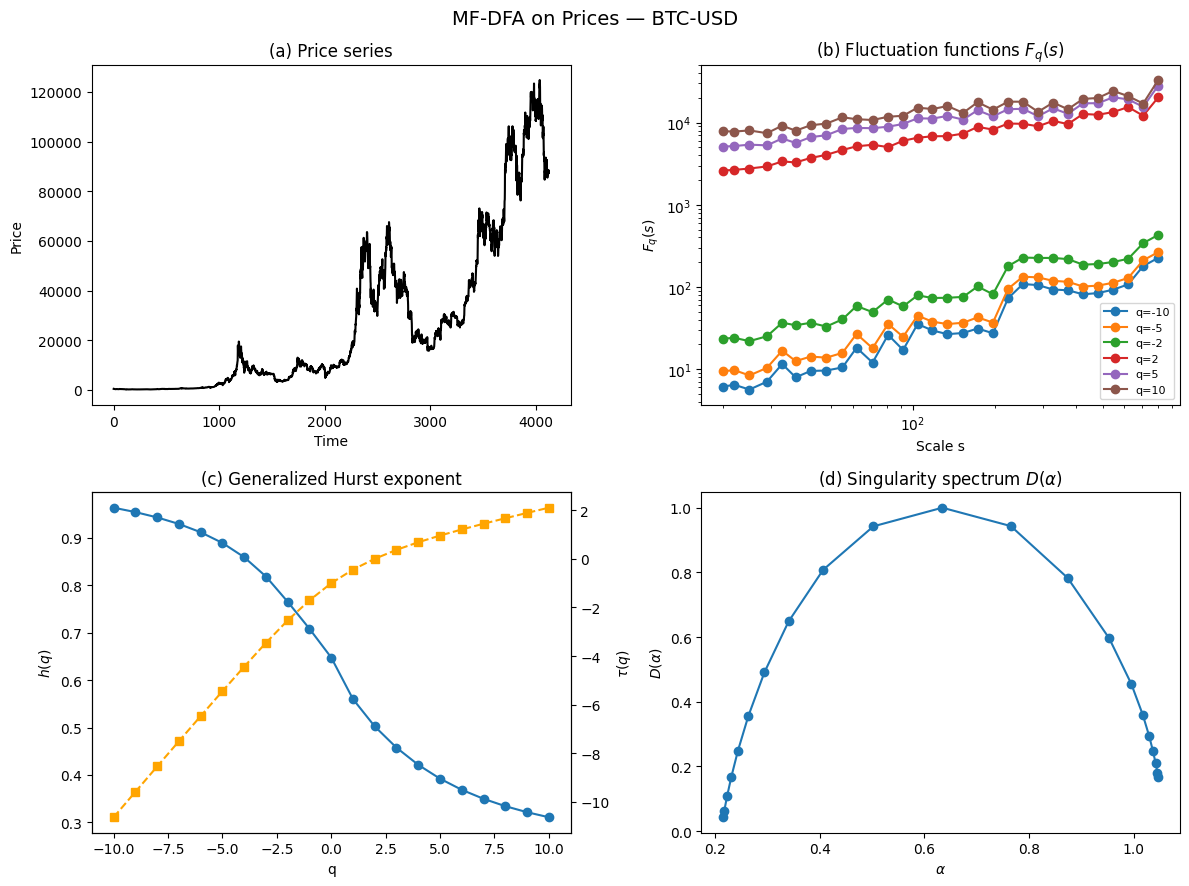

In [7]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

# =====================================
# PARAMETERS
# =====================================
tickers = ["AAPL", "MSFT", "GOOG", "TSLA", "AMZN","GC=F","BTC-USD"]
start = "2010-01-01"
end = "2026-01-01"

q_vals = np.arange(-10, 11, 1)
scale_min = 20
scale_max = 800
n_scales = 30

# =====================================
# MF-DFA FOR PRICES (NO INTEGRATION)
# =====================================
def mfdfa_prices(x, q_vals, scale_min, scale_max, n_scales):
    scales = np.unique(
        np.logspace(np.log10(scale_min), np.log10(scale_max), n_scales).astype(int)
    )

    Fqs = np.zeros((len(q_vals), len(scales)))

    for i, s in enumerate(scales):
        Ns = len(x) // s
        rms = []

        for v in range(Ns):
            seg = x[v*s:(v+1)*s]
            t = np.arange(s)
            p = np.polyfit(t, seg, 1)
            trend = np.polyval(p, t)
            rms.append(np.sqrt(np.mean((seg - trend)**2)))

        rms = np.array(rms)
        rms = rms[rms > 0]

        for j, q in enumerate(q_vals):
            if q == 0:
                Fqs[j, i] = np.exp(0.5 * np.mean(np.log(rms**2)))
            else:
                Fqs[j, i] = (np.mean(rms**q))**(1/q)

    hq = np.array([
        np.polyfit(np.log(scales), np.log(Fqs[j]), 1)[0]
        for j in range(len(q_vals))
    ])

    return scales, Fqs, hq

# =====================================
# LOOP OVER STOCKS
# =====================================
for ticker in tickers:
    print(f"Processing {ticker}...")

    data = yf.download(ticker, start=start, end=end, progress=False)
    price = data["Close"].dropna().values

    scales, Fqs, hq = mfdfa_prices(
        price, q_vals, scale_min, scale_max, n_scales
    )

    # Multifractal exponents
    tau_q = hq * q_vals - 1
    alpha = np.gradient(tau_q, q_vals)
    D_alpha = q_vals * alpha - tau_q

    # =====================================
    # PLOTS (4-panel like the paper)
    # =====================================
    fig, axs = plt.subplots(2, 2, figsize=(12, 9))
    fig.suptitle(f"MF-DFA on Prices — {ticker}", fontsize=14)

    # (a) Price series
    axs[0, 0].plot(price, color="black")
    axs[0, 0].set_title("(a) Price series")
    axs[0, 0].set_xlabel("Time")
    axs[0, 0].set_ylabel("Price")

    # (b) F_q(s) vs s
    for q in [-10, -5, -2, 2, 5, 10]:
        idx = np.where(q_vals == q)[0][0]
        axs[0, 1].loglog(scales, Fqs[idx], 'o-', label=f"q={q}")

    axs[0, 1].set_title("(b) Fluctuation functions $F_q(s)$")
    axs[0, 1].set_xlabel("Scale s")
    axs[0, 1].set_ylabel("$F_q(s)$")
    axs[0, 1].legend(fontsize=8)

    # (c) h(q) and tau(q)
    axs[1, 0].plot(q_vals, hq, 'o-', label="$h(q)$")
    axs[1, 0].set_title("(c) Generalized Hurst exponent")
    axs[1, 0].set_xlabel("q")
    axs[1, 0].set_ylabel("$h(q)$")

    ax2 = axs[1, 0].twinx()
    ax2.plot(q_vals, tau_q, 's--', color="orange", label=r"$\tau(q)$")
    ax2.set_ylabel(r"$\tau(q)$")

    # (d) Singularity spectrum
    axs[1, 1].plot(alpha, D_alpha, 'o-')
    axs[1, 1].set_title("(d) Singularity spectrum $D(\\alpha)$")
    axs[1, 1].set_xlabel(r"$\alpha$")
    axs[1, 1].set_ylabel(r"$D(\alpha)$")

    plt.tight_layout()
    plt.show()
